# Notebook 04 — Evaluation: which results are real?

**Project:** deepbook-flowcast — predicting short-term price moves on DeepBook, Sui's on-chain order book.

Notebooks 02–03 report single numbers (e.g. "0.463"). Here we ask **how sure** we can be about them, and answer the
lead-lag question directly.

- **Confidence intervals by day-level bootstrap:** September has 30 days. Draw 30 days at random *with repeats*, score
  every model on that "fake September", repeat 1,000 times; the middle 95% of the scores is the interval. Days, not
  seconds, because neighbouring seconds are near-duplicates (resampling seconds would give falsely tiny intervals).
- **Paired comparisons:** both models are scored on the **same** resampled days, so "September was easy" cancels out.
  A lift counts as **real** only if its interval excludes 0.
- **Lead-lag:** correlation of DeepBook's 1-second return with Binance's return k seconds earlier.

| Step | Command | Output |
|---|---|---|
| Bootstrap, comparisons, confident calls, lead-lag (Sep 2025) | `uv run flowcast evaluate` (commit `ff89a6d`) | `runs/<time>_eval/` |
| Walk-forward | _to do_ | |
| October test (once) + 2026 regime shift | _to do_ | |

## 1. Imports

In [1]:
# Import libraries
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from flowcast.config import RUNS

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.dpi"] = 110

EVAL = sorted(RUNS.glob("*_eval"))[-1]          # the latest evaluation run
cfg = json.loads((EVAL / "config.json").read_text())
scores, comps, conf, ll = (pd.read_csv(EVAL / f"{n}.csv") for n in ("scores", "comparisons", "confidence", "leadlag"))
print(EVAL.name, "| models:", cfg["model_runs"], "| bootstrap:", cfg["bootstrap"])

20261009-232053_eval | models: {'logreg': '20261009-182404_logreg', 'lgbm': '20261009-191600_lgbm'} | bootstrap: {'resamples': 1000, 'seed': 0, 'unit': 'day'}


## 2. Scores with 95% intervals

Each dot is a model's September macro F1; the bar is its 95% interval. Non-overlapping bars are clearly different;
for close calls use the paired comparisons in section 3 (they are much tighter).

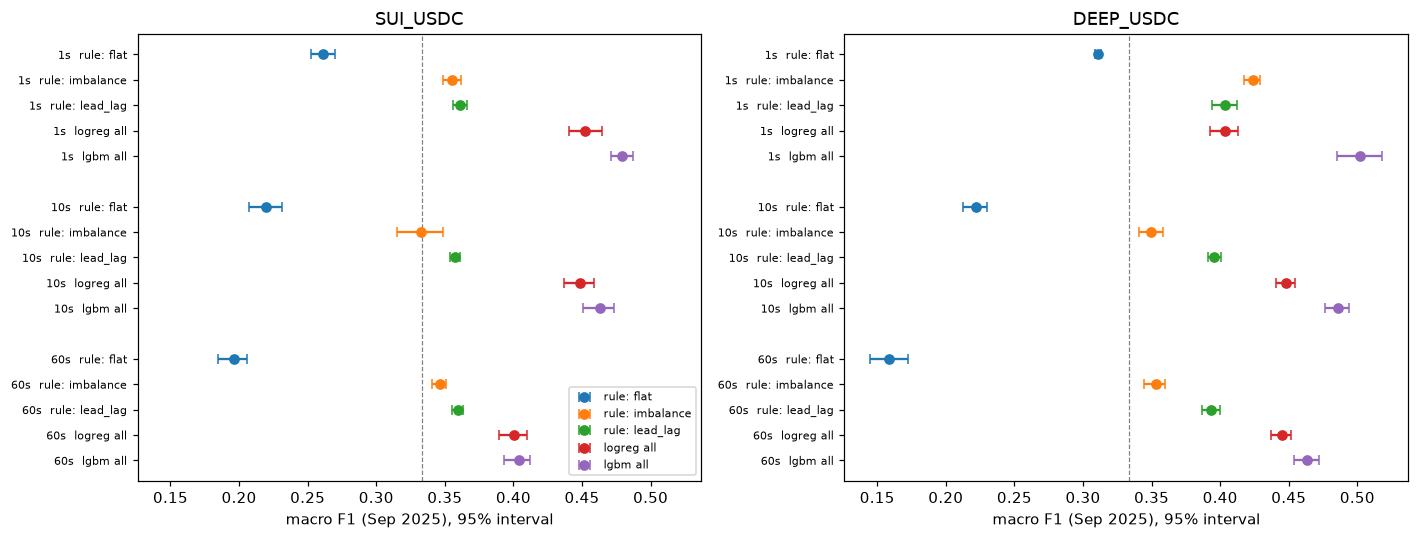

In [2]:
# Forest plot: rules vs logistic regression vs LightGBM (+ Binance features), per pool and horizon
show = ["rule: flat", "rule: imbalance", "rule: lead_lag", "logreg all", "lgbm all"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True)
for ax, pool in zip(axes, ["SUI_USDC", "DEEP_USDC"]):
    s = scores[(scores.pool == pool) & scores.model.isin(show)]
    labels = []
    for i, (h, g) in enumerate(s.groupby("horizon", sort=False)):
        for j, m in enumerate(show):
            r = g[g.model == m].iloc[0]
            y = i * (len(show) + 1) + j
            ax.errorbar(r.macro_f1, y, xerr=[[r.macro_f1 - r.lo], [r.hi - r.macro_f1]], fmt="o",
                        color=f"C{j}", capsize=3, label=m if i == 0 else None)
            labels.append((y, f"{h}  {m}"))
    ax.set_yticks([y for y, _ in labels]); ax.set_yticklabels([t for _, t in labels], fontsize=7)
    ax.invert_yaxis(); ax.set_title(pool); ax.set_xlabel("macro F1 (Sep 2025), 95% interval")
    ax.axvline(1 / 3, color="grey", ls="--", lw=0.8)
axes[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 3. Paired comparisons: which lifts are real?

In [3]:
c = comps.copy()
c["diff [95% interval]"] = c.apply(lambda r: f"{r['diff']:+.3f} [{r.lo:+.3f}, {r.hi:+.3f}]", axis=1)
c.pivot_table(index=["comparison"], columns=["pool", "horizon"], values="diff [95% interval]", aggfunc="first")

pool                                         DEEP_USDC  \
horizon                                            10s   
comparison                                               
Binance adds (lgbm)            +0.023 [+0.020, +0.025]   
Binance adds (logreg)          +0.032 [+0.030, +0.036]   
lgbm vs best rule              +0.090 [+0.083, +0.096]   
lgbm vs logreg                 +0.037 [+0.031, +0.044]   
logreg vs best rule            +0.053 [+0.045, +0.059]   
own model vs SUI model (lgbm)  +0.043 [+0.037, +0.049]   

pool                                                    \
horizon                                             1s   
comparison                                               
Binance adds (lgbm)            +0.021 [+0.018, +0.023]   
Binance adds (logreg)          +0.018 [+0.016, +0.020]   
lgbm vs best rule              +0.078 [+0.064, +0.094]   
lgbm vs logreg                 +0.099 [+0.079, +0.118]   
logreg vs best rule            -0.021 [-0.031, -0.010]   
own model vs SUI model (lgbm)  +0.239 [+0.214, +0.265]   

pool                                                    \
horizon                                            60s   
comparison                                               
Binance adds (lgbm)            +0.018 [+0.015, +0.021]   
Binance adds (logreg)          +0.029 [+0.026, +0.033]   
lgbm vs best rule              +0.070 [+0.060, +0.079]   
lgbm vs logreg                 +0.018 [+0.014, +0.022]   
logreg vs best rule            +0.052 [+0.042, +0.060]   
own model vs SUI model (lgbm)  +0.041 [+0.034, +0.049]   

pool                                          SUI_USDC  \
horizon                                            10s   
comparison                                               
Binance adds (lgbm)            +0.005 [+0.004, +0.006]   
Binance adds (logreg)          +0.007 [+0.005, +0.008]   
lgbm vs best rule              +0.105 [+0.095, +0.114]   
lgbm vs logreg                 +0.014 [+0.012, +0.016]   
logreg vs best rule            +0.091 [+0.081, +0.100]   
own model vs SUI model (lgbm)                      NaN   

pool                                                    \
horizon                                             1s   
comparison                                               
Binance adds (lgbm)            +0.014 [+0.012, +0.017]   
Binance adds (logreg)          +0.013 [+0.011, +0.015]   
lgbm vs best rule              +0.118 [+0.110, +0.126]   
lgbm vs logreg                 +0.027 [+0.020, +0.033]   
logreg vs best rule            +0.091 [+0.080, +0.103]   
own model vs SUI model (lgbm)                      NaN   

pool                                                    
horizon                                            60s  
comparison                                              
Binance adds (lgbm)            +0.006 [+0.004, +0.008]  
Binance adds (logreg)          +0.005 [+0.004, +0.006]  
lgbm vs best rule              +0.044 [+0.036, +0.051]  
lgbm vs logreg                 +0.003 [+0.001, +0.006]  
logreg vs best rule            +0.041 [+0.031, +0.049]  
own model vs SUI model (lgbm)                      NaN

In [4]:
comps.groupby("verdict").size()

verdict
real     32
worse     1
dtype: int64

**Every lift is real** except one: logistic regression on DEEP_USDC at 1 s is **reliably worse** than the imbalance rule
(it can't express a threshold). Even small effects hold up: "Binance adds +0.005 at SUI 10 s" has an interval of
[+0.004, +0.006]. The intervals are tight because the models are steady from day to day.

## 4. Confident calls: do they pay after costs?

For the most confident LightGBM calls (top 100% / 20% / 5% / 1% by `|P(UP) − P(DOWN)|`): the average move in the
predicted direction, the **average** cost of a taker round trip (spread at entry + 2 × ~1 bp fee), and the average net,
with a 95% interval on the net. Expected profit needs the **average** cost; the median spread understates it badly
because confident calls cluster in moments with occasionally very wide spreads.

In [5]:
conf[["pool", "horizon", "top_share", "calls", "directional_accuracy", "avg_move_bps", "avg_cost_bps",
      "avg_net_bps", "net_lo", "net_hi"]].round(3)

,pool,horizon,top_share,calls,directional_accuracy,avg_move_bps,avg_cost_bps,avg_net_bps,net_lo,net_hi
0,SUI_USDC,1s,1.00,2592000,0.618,0.137,3.403,-3.267,-3.420,-3.108
1,SUI_USDC,1s,0.20,518400,0.726,0.384,4.008,-3.624,-3.838,-3.396
2,SUI_USDC,1s,0.05,129600,0.774,0.550,4.575,-4.026,-4.400,-3.701
3,SUI_USDC,1s,0.01,25920,0.842,0.762,5.094,-4.331,-5.172,-3.737
4,SUI_USDC,10s,1.00,2592000,0.577,0.549,3.403,-2.855,-3.006,-2.694
5,SUI_USDC,10s,0.20,518400,0.659,1.300,3.815,-2.515,-2.708,-2.306
6,SUI_USDC,10s,0.05,129600,0.706,1.927,4.833,-2.906,-3.397,-2.471
7,SUI_USDC,10s,0.01,25920,0.762,3.450,8.803,-5.354,-7.267,-3.725
8,SUI_USDC,60s,1.00,2592000,0.540,0.704,3.403,-2.699,-2.873,-2.534
9,SUI_USDC,60s,0.20,518400,0.587,1.650,3.472,-1.822,-2.068,-1.565


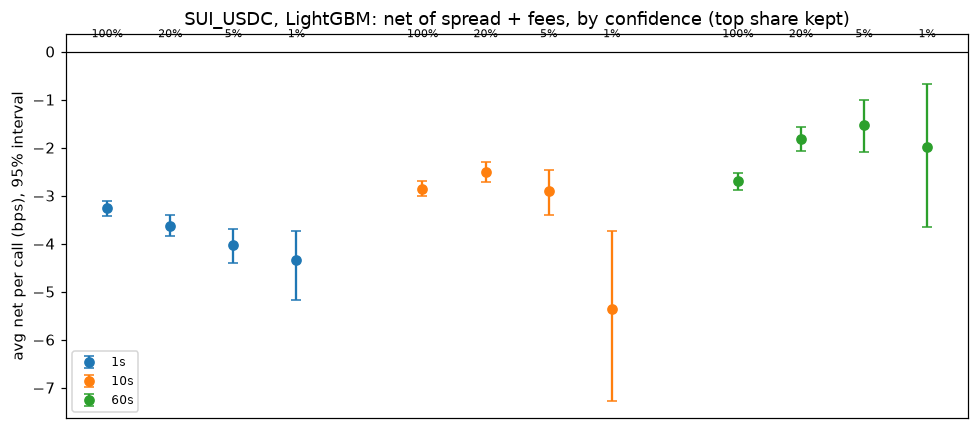

In [6]:
# Net per call with its interval (SUI_USDC): every bar stays below 0
s = conf[conf.pool == "SUI_USDC"]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (h, g) in enumerate(s.groupby("horizon", sort=False)):
    x = np.arange(len(g)) + i * (len(g) + 1)
    ax.errorbar(x, g.avg_net_bps, yerr=[g.avg_net_bps - g.net_lo, g.net_hi - g.avg_net_bps], fmt="o", capsize=3, label=h)
    for xi, q in zip(x, g.top_share):
        ax.annotate(f"{q:.0%}", (xi, 0.3), ha="center", fontsize=7)
ax.axhline(0, color="k", lw=0.8); ax.set_xticks([]); ax.set_ylabel("avg net per call (bps), 95% interval")
ax.set_title("SUI_USDC, LightGBM: net of spread + fees, by confidence (top share kept)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**No confidence level is profitable as a taker**, in either pool. The best case anywhere is SUI 60 s, top 1%:
about −2.0 bps per call [−3.7, −0.7]. On DEEP_USDC the average cost (~15 bps, mostly spread) swamps everything.
The more confident the call, the wider the spread it happens in: many confident "moves" are the mid snapping back as a
wide spread closes — something a **maker** earns and a taker pays. That's the angle worth testing next.

## 5. Lead-lag: does DeepBook trail Binance?

Correlation between DeepBook's 1-second mid return at time t and Binance's 1-second return at t − lag.
A peak at a **positive** lag means Binance moves first.

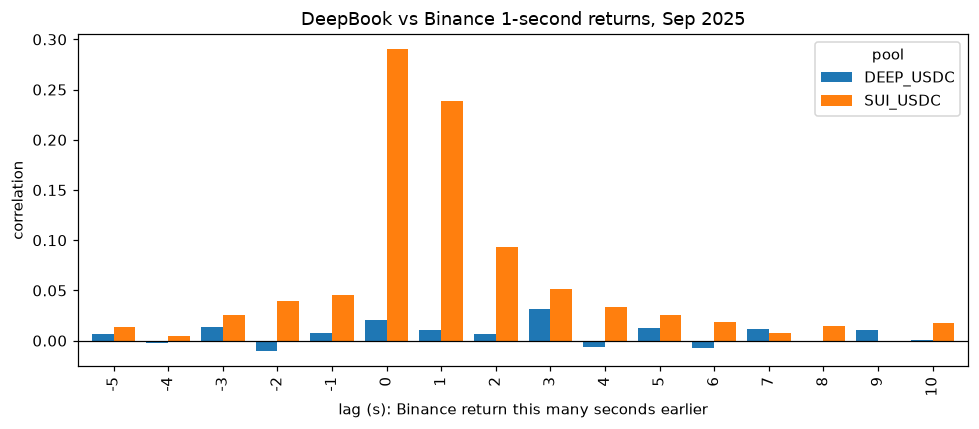

lag_s,-5,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8,9,10
pool,,,,,,,,,,,,,,,,
DEEP_USDC,0.006,-0.003,0.014,-0.010,0.007,0.02,0.010,0.007,0.031,-0.006,0.013,-0.007,0.011,-0.001,0.011,0.001
SUI_USDC,0.014,0.005,0.026,0.039,0.046,0.29,0.239,0.093,0.052,0.033,0.025,0.019,0.007,0.015,-0.000,0.018


In [7]:
t = ll.pivot(index="lag_s", columns="pool", values="corr")
ax = t.plot.bar(figsize=(9, 4), width=0.8)
ax.axhline(0, color="k", lw=0.8); ax.set_xlabel("lag (s): Binance return this many seconds earlier")
ax.set_ylabel("correlation"); ax.set_title("DeepBook vs Binance 1-second returns, Sep 2025")
plt.tight_layout(); plt.show()
t.round(3).T

**SUI_USDC: Binance leads by about 0–2 seconds.** Correlation is 0.29 within the same second and 0.24 when Binance is one
second earlier, 0.09 at two, and fades after that; DeepBook rarely leads (negative lags ≤ 0.05). DEEP_USDC shows almost
no 1-second correlation with the DEEP perpetual: its mid barely moves second to second. This matches the models:
Binance adds a small but real amount on top of DeepBook's own order flow.

Caveat: Binance timestamps are exchange time, DeepBook's are Sui checkpoint time; a few hundred milliseconds of clock
offset would blur lag 0 and lag 1 together but not change the conclusion.

## 6. Still to do

- **Walk-forward:** retrain weekly through September (expanding window), test each next week: is the edge stable, and
  does retraining beat the frozen August model?
- **October test (once)** with the final models trained on Aug + Sep, split before / after the Oct 10 crash; then the
  frozen 2025 models on Jul–Sep 2026 (regime shift).
- Slices by volatility tercile and market-maker state; the maker angle for confident calls.